# 01b Preprocess the indicators: the routes towards Switzerland and the neighbouring countries

**Purpose:** Load and check the two indicators we use next to the series' own past, state what is known at the cutoff, and explore each one before the test period: the **detections on the routes towards Switzerland** (Frontex, sections 1 to 6) and the **asylum applications in Germany, Austria, France and Italy** (Eurostat, sections 7 to 10).
**Input:** `../data/raw/frontex_detections_by_route_monthly.csv`, `../data/raw/estat_migr_asyappctzm_neighbours_en.csv` and `../data/processed/asylum_clean.csv`.
**Output:** `../data/processed/routes_clean.csv`, `../data/processed/neighbours_clean.csv` and two figures in `../output/figures/`.

**Which indicators?** Only data that are published in time for our cutoff in **every** month, from one source with one definition. Both indicators here are known up to month $t-1$ at a forecast origin $t$. We also looked at three other sources and did not keep them: UNHCR's monthly arrivals (the same numbers as Frontex one month earlier, but their series start only in 2014 to 2018, so not available in time for most of the backtest), UCDP's conflict deaths (final, revised numbers that nobody had at the time, ending in December 2025) and the nationalities of the applicants (needed only for the conflict index).

The test period (2024-10 to 2026-09) is only described, never used to choose anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the raw data

Frontex publishes the number of **detections of illegal border-crossings** at the external borders of the EU and the Schengen countries, every month, by route. We aggregated the published file (one row per route and nationality) to one column per route; `SOURCES.md` says how, and gives the totals we checked.

**Careful with the meaning:** Frontex counts *detections*, not persons. The same person can be detected several times, for example once on the Eastern Mediterranean route and again on the Western Balkan route. The numbers are an indicator of movement towards Europe, not a count of people.

In [2]:
routes = pd.read_csv("../data/raw/frontex_detections_by_route_monthly.csv")
routes["month"] = pd.to_datetime(routes["month"], format="%Y-%m")
routes = routes.set_index("month")

print("Number of months:", routes.shape[0])
print("First month:", routes.index[0])
print("Last month: ", routes.index[-1])
routes.head()

Number of months: 213
First month: 2009-01-01 00:00:00
Last month:  2026-09-01 00:00:00


,eastern_mediterranean,central_mediterranean,western_mediterranean,western_african,western_balkan,eastern_borders,circular_route_from_albania_to_greece,black_sea,other
month,,,,,,,,,
2009-01-01,2730,1491,508,361,177,93,1521,0,0
2009-02-01,2228,1221,302,685,327,82,1884,1,0
2009-03-01,2870,2519,656,392,355,133,2368,0,1
2009-04-01,3298,1981,423,0,161,112,4207,0,0
2009-05-01,3750,610,557,0,214,115,5512,0,0


## 2. Check the data

The same checks as in `01_preprocess.ipynb` (notebooks 04 and 106): missing values, missing months, and values of zero (the logarithm of 0 does not exist).

In [3]:
first, last = routes.index[0], routes.index[-1]
n_expected = 12 * (last.year - first.year) + (last.month - first.month) + 1
print("Expected number of months:", n_expected, "| in the data:", routes.shape[0])
print("Missing values:", routes.isna().sum().sum())
print()
print("Number of months with zero detections, per route:")
print((routes == 0).sum())

Expected number of months: 213 | in the data: 213
Missing values: 0

Number of months with zero detections, per route:
eastern_mediterranean                      0
central_mediterranean                      1
western_mediterranean                      0
western_african                           29
western_balkan                             0
eastern_borders                            0
circular_route_from_albania_to_greece      0
black_sea                                182
other                                    179
dtype: int64


**What we see.** The file has 213 months (January 2009 to September 2026), no missing value and no missing month. Some routes have months with zero detections: Central Mediterranean once, Western African 29 times, and the two small routes (Black Sea, Other) in most months. The three routes we use, apart from the single zero on the Central Mediterranean, never have a month with zero detections.

## 3. One indicator: the three routes towards Switzerland

We decided **before looking at any relationship with Swiss applications** (so that the choice cannot be fitted to the data, notebook 211) to use one indicator series: the sum of detections on the three routes that lead towards Switzerland:

- **Central Mediterranean** (sea arrivals in Italy and Malta, Switzerland's southern neighbour),
- **Eastern Mediterranean** (arrivals in Greece and Cyprus),
- **Western Balkan** (the land route through the Balkans towards Austria).

Why one series and not three: we have few months, so we keep the number of features small (Johannes' feedback). The sum also has no month with zero detections, unlike the Central Mediterranean route alone.

In [4]:
three_routes = ["central_mediterranean", "eastern_mediterranean", "western_balkan"]
routes["routes_to_switzerland"] = routes[three_routes].sum(axis=1)

print("Smallest monthly value of the sum:", routes["routes_to_switzerland"].min())
print("Share of all detections on all routes (2009-01 to 2026-09):",
      round(routes["routes_to_switzerland"].sum() / routes.drop(columns="routes_to_switzerland").sum().sum(), 3))

Smallest monthly value of the sum: 952
Share of all detections on all routes (2009-01 to 2026-09): 0.871


**What we see.** The sum of the three routes is never below 952 detections a month, so its logarithm always exists. Together, the three routes hold 87% of all detections in the file.

## 4. What is known at the cutoff?

The file we downloaded on 17 November 2026 is dated **4 November 2026** and its last month is **September 2026**. So, around the 15th of month $m$ (our cutoff), Frontex is known up to month $m-2$, one month less than our target, which is known up to $m-1$:

| At the cutoff (around the 15th of month $m$) | Last month known |
|---|---|
| Asylum applications in Switzerland (target) | $m-1$ = the forecast origin $t$ |
| Detections on the routes (Frontex file) | $m-2$ = $t-1$ |

We assume that Frontex published with the same delay in the past. **Rule for step D:** at a forecast origin $t$, a model may use the detections up to month $t-1$ only.

Like our target, the Frontex numbers are revised later ("Frontex regularly publishes updates", notes of the file). We use today's values, not the values first published each month; this is a limitation we report.

In [5]:
print("Last month in the Frontex file:", routes.index[-1], "(file dated 4 November 2026)")

Last month in the Frontex file: 2026-09-01 00:00:00 (file dated 4 November 2026)


## 5. Explore the indicator next to the target, before the test period

We join the indicator to the target by month with `merge` (notebook 04) and keep only the months before the test period, as in `01_preprocess.ipynb` (notebook 209: we do not look at the test period).

In [6]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])

both = pd.merge(clean, routes[["routes_to_switzerland"]].reset_index(), on="month", how="inner")
both = both[both["period"] != "test"].set_index("month")
both["log_routes"] = np.log(both["routes_to_switzerland"])

print("Months with both series, before the test period:", both.shape[0])
print("From", both.index[0], "to", both.index[-1])

Months with both series, before the test period: 189
From 2009-01-01 00:00:00 to 2024-09-01 00:00:00


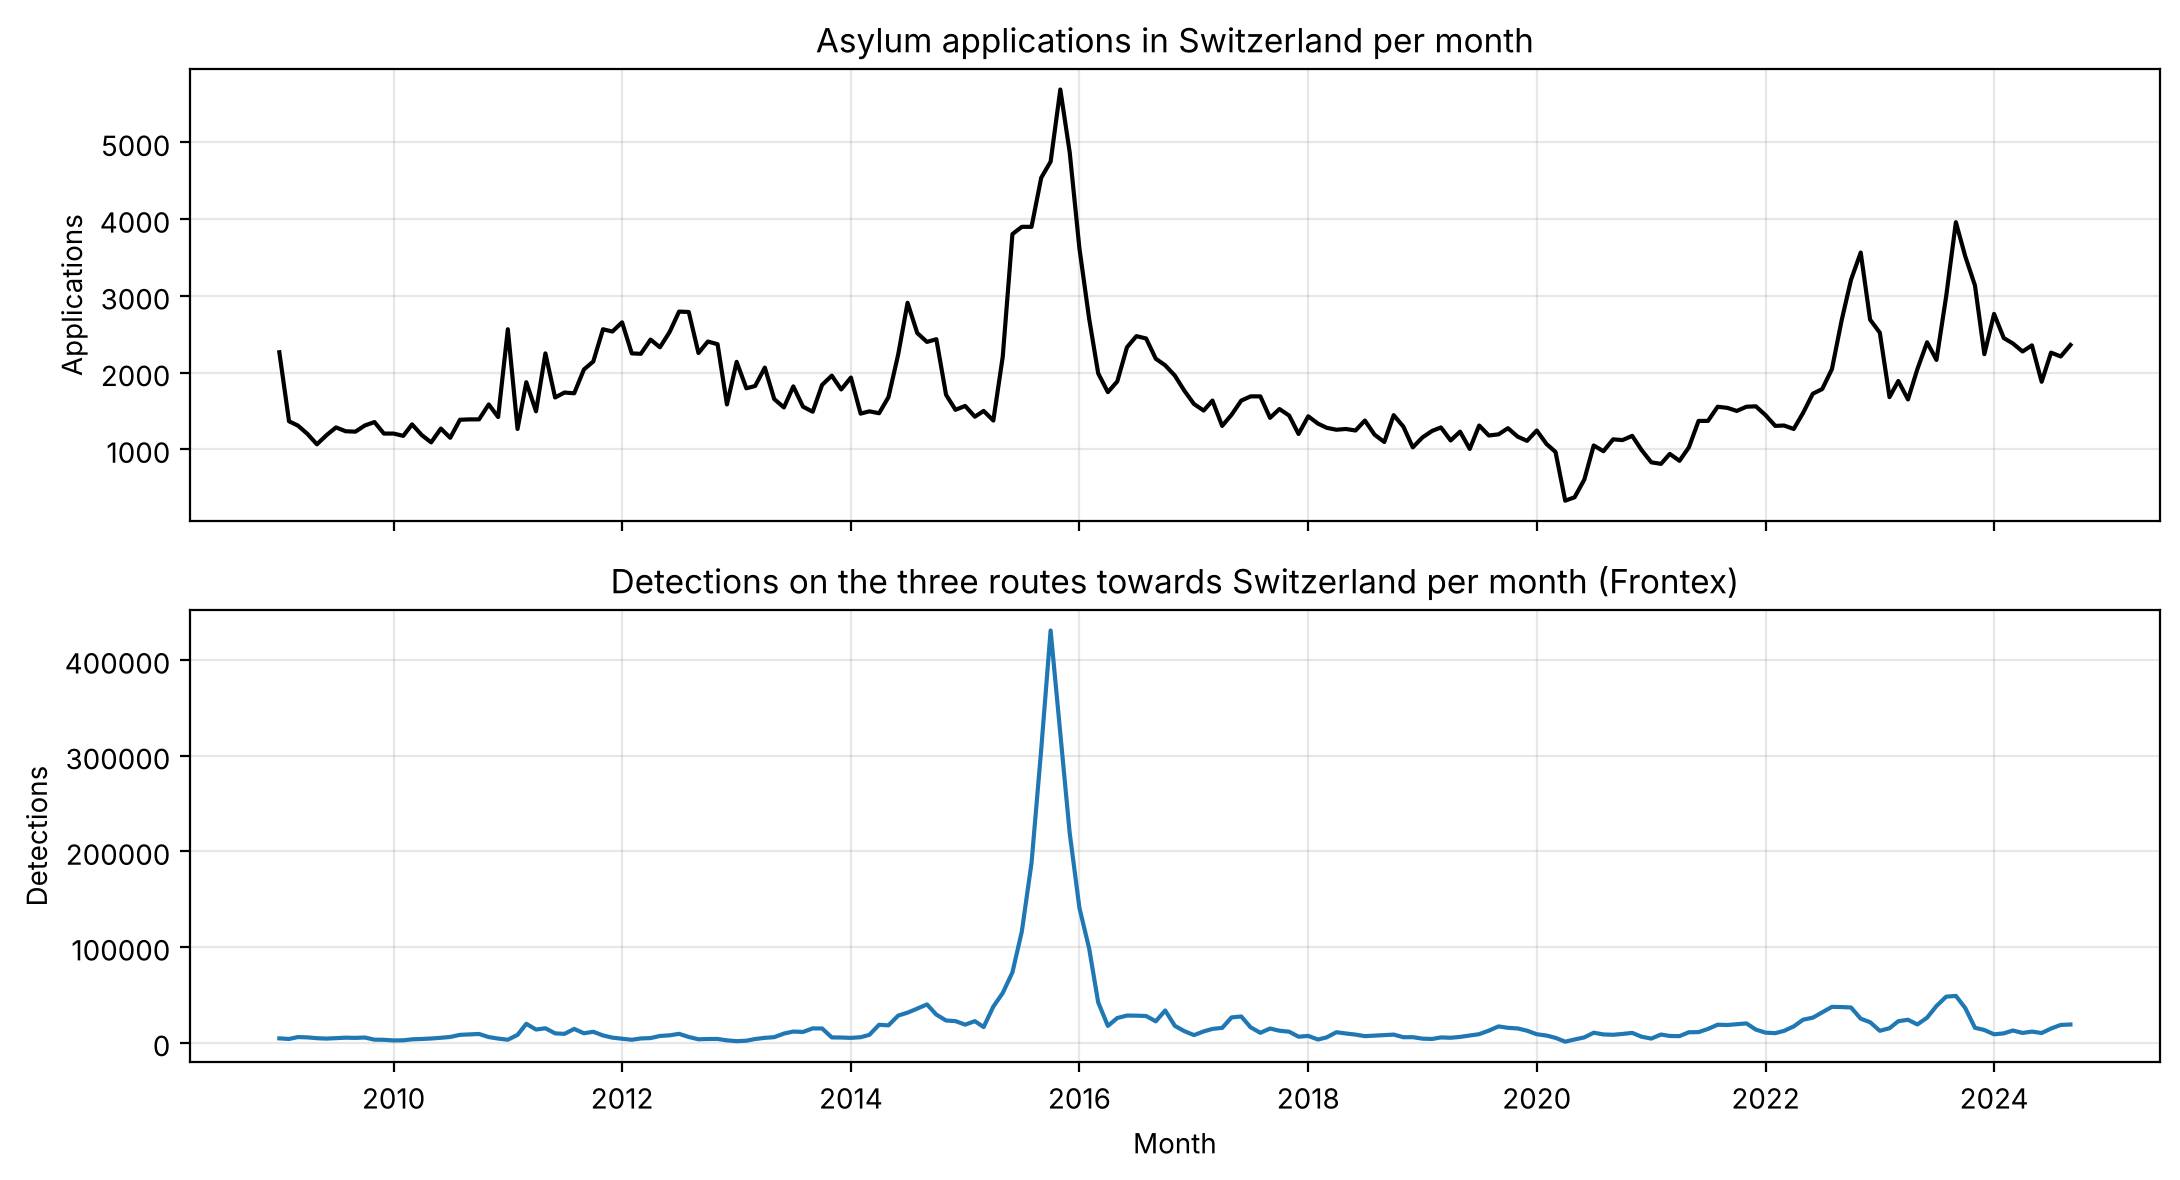

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(both.index, both["applicants_total"], color="black")
axes[0].set_title("Asylum applications in Switzerland per month")
axes[0].set_ylabel("Applications")
axes[1].plot(both.index, both["routes_to_switzerland"], color="tab:blue")
axes[1].set_title("Detections on the three routes towards Switzerland per month (Frontex)")
axes[1].set_ylabel("Detections")
axes[1].set_xlabel("Month")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01b_routes_and_applications.png")
plt.show()

In [8]:
# The highest months of the indicator (sort_values, notebook 02)
print(both["routes_to_switzerland"].sort_values(ascending=False).head(3))

month
2015-10-01    430879
2015-11-01    322656
2015-09-01    306699
Name: routes_to_switzerland, dtype: int64


**What we see.** The indicator is dominated by one huge peak: the three highest months are September to November 2015, with a maximum of 430,879 detections in October 2015, at about the same time as the highest months of applications in Switzerland (upper panel). Smaller rises appear on both panels in 2022 and 2023. Because the 2015 peak is so large, we work with the logarithm of the detections, as for the target.

### Do changes on the routes come before changes in Switzerland?

Notebook 200 showed that two trending series can look strongly correlated without any link (spurious correlation), and that differencing removes this. So we compare **monthly changes** of the logs, not the levels: the correlation between the change of applications in month $s$ and the change of detections $k$ months earlier, for $k = 0, \dots, 6$, with `np.corrcoef` (notebook 200).

This is a **description**, not a choice: the lag the indicator gets in step D is fixed by what is known at the cutoff (section 4), not by this table.

In [9]:
d_apps = np.diff(both["log_applicants"].to_numpy())     # change of log applications, month by month
d_routes = np.diff(both["log_routes"].to_numpy())        # change of log detections, month by month

def lagged_corr(k):
    # Correlation between the change of applications in month s and the change of detections in month s - k
    if k == 0:
        return np.corrcoef(d_apps, d_routes)[0, 1]
    return np.corrcoef(d_apps[k:], d_routes[:-k])[0, 1]

lag_table = pd.DataFrame({"correlation": [round(lagged_corr(k), 2) for k in range(7)]},
                         index=pd.Index(range(7), name="detections k months earlier"))
lag_table

,correlation
detections k months earlier,
0,0.31
1,0.35
2,0.08
3,0.07
4,-0.02
5,-0.08
6,-0.12


**What we see.** The change of applications in Switzerland is correlated with the change of detections in the same month (0.31) and one month earlier (0.35). With detections two or more months earlier, the correlation is close to zero (0.08 at $k = 2$, 0.07 at $k = 3$, and between −0.12 and −0.02 for $k = 4$ to $6$).

**What this means for us.** Movements on the routes show up in Switzerland almost at once, within about a month. But at the cutoff, the newest detection month we know is $t-1$, while the first month we forecast is $t+1$: the gap is at least two months, exactly where the correlation is close to zero. So we expect the indicator to add **little** to our forecasts. We still test it in step D, as planned, because only the backtest can tell; and if it does not help, that is an honest result: the information arrives too late for SEM's decision.

## 6. Save the clean indicator

We keep the month, the three routes, their sum and its logarithm (each value transformed on its own, so nothing leaks from the test period; notebook 209, Step 2).

In [10]:
routes["log_routes"] = np.log(routes["routes_to_switzerland"])
routes_clean = routes[three_routes + ["routes_to_switzerland", "log_routes"]].reset_index()
routes_clean.to_csv("../data/processed/routes_clean.csv", index=False)
print("Saved", routes_clean.shape[0], "months and the columns", list(routes_clean.columns))

Saved 213 months and the columns ['month', 'central_mediterranean', 'eastern_mediterranean', 'western_balkan', 'routes_to_switzerland', 'log_routes']


## 7. A second indicator: applications in the neighbouring countries

People who come to Switzerland often travel through, or first apply in, Germany, Austria, France or Italy. We take the **same Eurostat dataset and the same filters as our target** (`migr_asyappctzm`, all citizenships, applicant type TOTAL) for these four countries, and Switzerland again as a check. The file is Eurostat's SDMX-CSV format: one row per country and month.

In [11]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")
months = clean.index
mkey = months.strftime("%Y-%m")          # months as text, e.g. "2015-09", to match the raw file
TEST_START = pd.Timestamp("2024-10-01")

nb_raw = pd.read_csv("../data/raw/estat_migr_asyappctzm_neighbours_en.csv")
print("Rows:", nb_raw.shape[0], "| countries:", sorted(nb_raw["geo"].unique()),
      "| applicant:", nb_raw["applicant"].unique(), "| last update:", nb_raw["LAST UPDATE"].iloc[0])
print("Flags:")
print(nb_raw.loc[nb_raw["OBS_FLAG"].notna(), ["geo", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]].to_string(index=False))

neighbours = nb_raw.pivot(index="TIME_PERIOD", columns="geo", values="OBS_VALUE").reindex(mkey)
neighbours.index = months
same = (neighbours["CH"] == clean["applicants_total"]).sum()
print()
print("Switzerland identical to our target in", same, "of", len(months), "months")
print("Missing months per country:")
print(neighbours[["DE", "AT", "FR", "IT"]].isna().sum().to_string())

Rows: 1124 | countries: ['AT', 'CH', 'DE', 'FR', 'IT'] | applicant: <StringArray>
['TOTAL']
Length: 1, dtype: str | last update: 18/11/26 11:00:00
Flags:
geo TIME_PERIOD  OBS_VALUE OBS_FLAG
 IT     2026-07       5165        b

Switzerland identical to our target in 225 of 225 months
Missing months per country:
geo
DE    1
AT    0
FR    0
IT    0


**What we see.** The file has 1,124 rows: five countries, January 2008 to September 2026, all with applicant type TOTAL (the same definition as our target), Eurostat update of 18 November 2026. **Switzerland is identical to our target in all 225 months**, so the two downloads are consistent. Germany is missing September 2026, and Italy has a break in series (flag `b`) in July 2026, when the new EU asylum rules started. Both are in the test period, which this step does not use.

## 8. What is known at the cutoff, and the series we keep

Eurostat publishes a month about six weeks after its end (Switzerland's September 2026 appeared on 13 November). At the cutoff around the 15th of month $m$, the forecast origin is $t = m-1$, so the newest neighbour month we may use is **$t-1$**, the same as for the routes.

We keep one series, the sum of the four countries, as a **log** (counts, never zero); the changes are built in the estimation notebook. `min_count=4` leaves a month empty unless all four countries are known, so a missing country never looks like a fall.

In [12]:
neighbours_clean = pd.DataFrame(index=months)
neighbours_clean["log_neighbours"] = np.log(neighbours[["DE", "AT", "FR", "IT"]].sum(axis=1, min_count=4))
neighbours_clean.index.name = "month"
print(neighbours_clean.describe().round(2))
print("Missing:", neighbours_clean["log_neighbours"].isna().sum(), "month(s):",
      list(neighbours_clean.index[neighbours_clean["log_neighbours"].isna()].strftime("%Y-%m")))

       log_neighbours
count          224.00
mean            10.21
std              0.68
min              8.87
25%              9.61
50%             10.36
75%             10.67
max             11.67
Missing: 1 month(s): ['2026-09']


## 9. Explore the indicator next to the target, before the test period

As for the routes (section 5), we look only at the months before the test period: do the monthly changes in the neighbouring countries move together with the Swiss change in the same month, or in the following months (a lead)? We correlate the change in month $s$ with the change of Swiss log applications in month $s + k$.

k (months later)     0     1     2     3
correlation       0.59  0.05 -0.04 -0.07


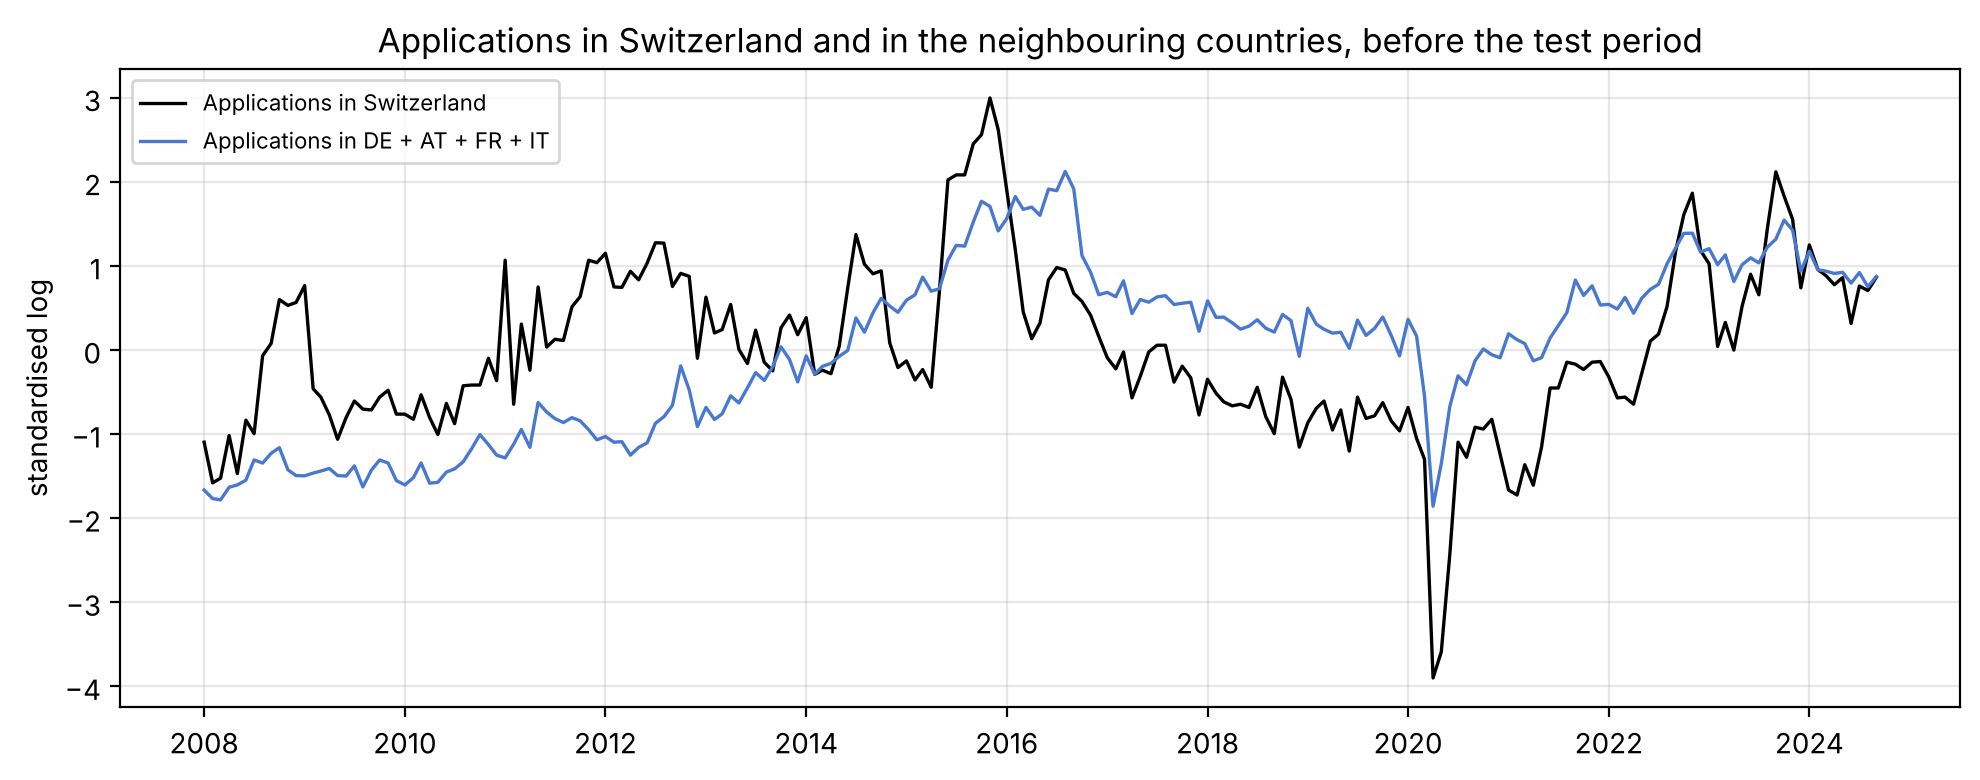

In [13]:
log_y = clean["log_applicants"]
rows = []
for k in range(4):
    both = pd.DataFrame({"ind": neighbours_clean["log_neighbours"].diff(), "app": log_y.diff().shift(-k)})
    both = both[both.index < TEST_START - pd.DateOffset(months=k)].dropna()
    rows.append({"k (months later)": k, "correlation": round(both["ind"].corr(both["app"]), 2)})
print(pd.DataFrame(rows).set_index("k (months later)").T)

before = months < TEST_START
a = (log_y - log_y[before].mean()) / log_y[before].std()
s = neighbours_clean["log_neighbours"]
z = (s - s[before].mean()) / s[before].std()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(months[before], a[before], color="black", lw=1.2, label="Applications in Switzerland")
ax.plot(months[before], z[before], lw=1.2, label="Applications in DE + AT + FR + IT")
ax.set_ylabel("standardised log")
ax.set_title("Applications in Switzerland and in the neighbouring countries, before the test period")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01b_neighbours_and_applications.png")
plt.show()

**What we see.** The change of applications in Germany, Austria, France and Italy moves strongly with the Swiss change **in the same month** (correlation 0.59), but not with the following months (0.05, −0.04, −0.07). In the figure, the two series follow the same big swings: 2015-16, the drop of 2020 and the rise of 2022-23.

**What this means for us.** The neighbouring countries tell us what happens in Switzerland in the same month, and that is the month we cannot use: at the cutoff we know them only up to $t-1$, while we already know Switzerland up to $t$. As for the routes, we expect them to add little two months ahead; only the backtest can tell (`02c`).

## 10. Save the clean series

In [14]:
neighbours_clean.to_csv("../data/processed/neighbours_clean.csv")
print("Saved", neighbours_clean.shape[0], "months and the columns", list(neighbours_clean.columns))

Saved 225 months and the columns ['log_neighbours']


## Summary

**Routes (Frontex)**

- **Data:** Frontex detections by route, 213 months (2009-01 to 2026-09), complete; the three routes towards Switzerland (Central Mediterranean, Eastern Mediterranean, Western Balkan) hold 87% of all detections.
- **Indicator (chosen before looking at the target):** one series, the sum of the three routes, used in logs.
- **Known at the cutoff:** up to month $m-2$, so at a forecast origin $t$ the newest indicator month is $t-1$.
- **First look:** changes on the routes go together with changes in Switzerland in the same month and one month later, but not two or more months later, which is the gap we face at the cutoff.
- **Output:** `../data/processed/routes_clean.csv`.

**Neighbouring countries (Eurostat)**

- **Data:** Eurostat `migr_asyappctzm`, the same dataset and filters as our target, for Germany, Austria, France and Italy, 2008-01 to 2026-09; Switzerland in the same file is identical to our target in 225 of 225 months. Germany misses September 2026, Italy has a break in series in July 2026 (both in the test period).
- **Indicator:** one series, the sum of the four countries, in logs.
- **Known at the cutoff:** up to $t-1$, like the routes.
- **First look:** the change moves with the Swiss change in the same month (0.59), not in the following months (about 0).
- **Not kept:** UNHCR's monthly arrivals (not available in time before 2014 to 2018), UCDP's conflict deaths (revised final numbers, ending in December 2025) and the applicants' nationalities (only needed for the conflict index).
- **Output:** `../data/processed/neighbours_clean.csv`.